# Занятие 4. Модели управленияы запасами с учетом дефицита поставок
##### 1. Потребность сборочного предприятия в деталях некоторого типа составляет 120 000 деталей в год, причем эти детали расходуются в процессе производства равномерно и непрерывно. Детали заказываются раз в год и поставляются партиями одинакового объема, указанного в заказе. Хранение детали на складе стоит 0,5 ден. ед. в сутки, а поставка партии — 10 000 ден. ед. Задержка производства из-за отсутствия деталей недопустима. Определить наиболее экономичный объем партии и интервал между поставками, которые нужно указать в заказе, дефицит недопустим. Срок выполнения поставки - 20 дней. Определить наиболее экономичный объем партии поставки и интервал между поставками, если известно, что отсутствие одной детали приносит убытки в 5 ден. ед.
##### 2. Потребность сборочного предприятия в деталях некоторого типа составляет 15000 деталей в месяц, причем эти детали расходуются в процессе производства равномерно и непрерывно. Детали заказываются раз в неделю и поставляются партиями одинакового объема, указанного в заказе. Хранение детали на складе стоит 1 ден. ед. в сутки, а поставка партии — 1000 ден. ед. Задержка производства из-за отсутствия деталей недопустима. Определить наиболее экономичный объем партии и интервал между поставками, которые нужно указать в заказе, дефицит недопустим. Срок выполнения поставки - 3 дня. Определить наиболее экономичный объем партии поставки и интервал между поставками, если известно, что отсутствие одной детали приносит убытки в 5 ден. ед.


=== Задача 1 ===

Базовая модель EOQ:
- Оптимальный размер заказа: 3626.39 единиц
- Интервал между поставками: 11.03 дней
- Количество заказов в год: 33.09
- Общие затраты: 661815.68 ден. ед.

Модель с учетом дефицита:
- Оптимальный размер заказа: 22207.00 единиц
- Максимальный уровень запаса: 21908.90 единиц
- Максимальный уровень дефицита: 298.09 единиц
- Интервал между поставками: 67.55 дней

Дополнительные показатели:
- Точка перезаказа: 6575.34 единиц
- Страховой запас: 241.86 единиц
        

=== Задача 2 ===

Базовая модель EOQ:
- Оптимальный размер заказа: 993.13 единиц
- Интервал между поставками: 2.01 дней
- Количество заказов в год: 181.25
- Общие затраты: 362491.38 ден. ед.

Модель с учетом дефицита:
- Оптимальный размер заказа: 8543.20 единиц
- Максимальный уровень запаса: 8485.28 единиц
- Максимальный уровень дефицита: 57.92 единиц
- Интервал между поставками: 17.32 дней

Дополнительные показатели:
- Точка перезаказа: 1479.45 единиц
- Страховой запас: 140.51 единиц
     

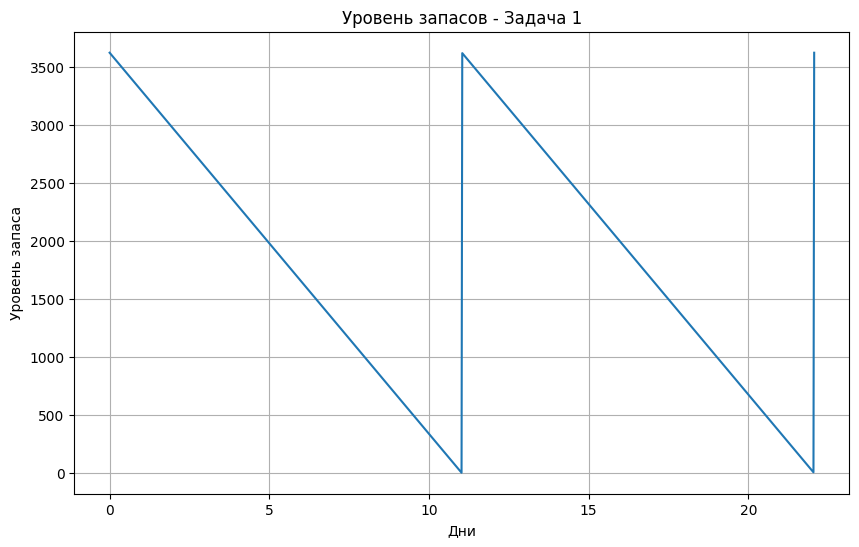

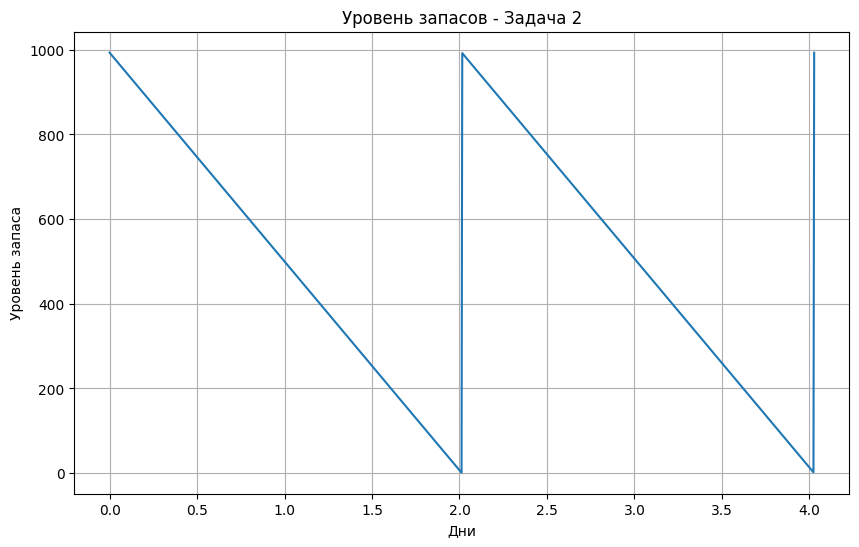

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

class InventoryOptimizer:
    def __init__(self):
        # Константы для задачи 1
        self.TASK1 = {
            'demand': 120000,  # Годовая потребность
            'order_cost': 10000,  # Стоимость заказа
            'holding_cost': 0.5 * 365,  # Годовая стоимость хранения
            'lead_time': 20,  # Время выполнения заказа
            'shortage_cost': 5  # Убытки от дефицита
        }
        
        # Константы для задачи 2
        self.TASK2 = {
            'demand': 15000 * 12,  # Годовая потребность
            'order_cost': 1000,  # Стоимость заказа
            'holding_cost': 1 * 365,  # Годовая стоимость хранения
            'lead_time': 3,  # Время выполнения заказа
            'shortage_cost': 5  # Убытки от дефицита
        }

    def calculate_basic_eoq(self, D, S, H):
        """
        Расчет базовой модели EOQ без дефицита
        D - годовая потребность
        S - стоимость заказа
        H - стоимость хранения
        """
        Q = math.sqrt((2 * D * S) / H)
        T = (Q / D) * 365  # интервал между поставками в днях
        N = D / Q  # количество заказов в год
        TC = (D * S / Q) + (Q * H / 2)  # общие затраты
        return Q, T, N, TC

    def calculate_eoq_with_shortages(self, D, S, H, p):
        """
        Расчет EOQ с учетом дефицита
        p - стоимость дефицита на единицу
        """
        Q = math.sqrt((2 * D * S * (H + p)) / (H * p))
        S_max = Q * math.sqrt(H / (H + p))  # максимальный уровень запаса
        B_max = Q - S_max  # максимальный уровень дефицита
        T = (Q / D) * 365
        return Q, S_max, B_max, T

    def calculate_reorder_point(self, D, L):
        """Расчет точки перезаказа"""
        daily_demand = D / 365
        return daily_demand * L

    def calculate_safety_stock(self, D, L, service_level=0.95):
        """Расчет страхового запаса"""
        daily_demand = D / 365
        # Предполагаем стандартное отклонение спроса 10% от среднего
        std_dev = daily_demand * 0.1
        z_score = 1.645  # для 95% уровня обслуживания
        return z_score * std_dev * math.sqrt(L)

    def plot_inventory_levels(self, Q, T, D, title):
        """Визуализация уровня запасов"""
        days = np.linspace(0, T*2, 1000)
        inventory = []
        
        for day in days:
            if day % T == 0:
                current_level = Q
            else:
                current_level = Q - (D/365) * (day % T)
            inventory.append(max(0, current_level))

        plt.figure(figsize=(10, 6))
        plt.plot(days, inventory)
        plt.title(title)
        plt.xlabel('Дни')
        plt.ylabel('Уровень запаса')
        plt.grid(True)
        plt.show()

    def solve_and_display(self):
        # Решение задачи 1
        print("\n=== Задача 1 ===")
        Q1, T1, N1, TC1 = self.calculate_basic_eoq(
            self.TASK1['demand'],
            self.TASK1['order_cost'],
            self.TASK1['holding_cost']
        )
        
        Q1_shortage, S1_max, B1_max, T1_shortage = self.calculate_eoq_with_shortages(
            self.TASK1['demand'],
            self.TASK1['order_cost'],
            self.TASK1['holding_cost'],
            self.TASK1['shortage_cost']
        )
        
        ROP1 = self.calculate_reorder_point(self.TASK1['demand'], self.TASK1['lead_time'])
        SS1 = self.calculate_safety_stock(self.TASK1['demand'], self.TASK1['lead_time'])

        print(f"""
Базовая модель EOQ:
- Оптимальный размер заказа: {Q1:.2f} единиц
- Интервал между поставками: {T1:.2f} дней
- Количество заказов в год: {N1:.2f}
- Общие затраты: {TC1:.2f} ден. ед.

Модель с учетом дефицита:
- Оптимальный размер заказа: {Q1_shortage:.2f} единиц
- Максимальный уровень запаса: {S1_max:.2f} единиц
- Максимальный уровень дефицита: {B1_max:.2f} единиц
- Интервал между поставками: {T1_shortage:.2f} дней

Дополнительные показатели:
- Точка перезаказа: {ROP1:.2f} единиц
- Страховой запас: {SS1:.2f} единиц
        """)

        # Решение задачи 2
        print("\n=== Задача 2 ===")
        Q2, T2, N2, TC2 = self.calculate_basic_eoq(
            self.TASK2['demand'],
            self.TASK2['order_cost'],
            self.TASK2['holding_cost']
        )
        
        Q2_shortage, S2_max, B2_max, T2_shortage = self.calculate_eoq_with_shortages(
            self.TASK2['demand'],
            self.TASK2['order_cost'],
            self.TASK2['holding_cost'],
            self.TASK2['shortage_cost']
        )
        
        ROP2 = self.calculate_reorder_point(self.TASK2['demand'], self.TASK2['lead_time'])
        SS2 = self.calculate_safety_stock(self.TASK2['demand'], self.TASK2['lead_time'])

        print(f"""
Базовая модель EOQ:
- Оптимальный размер заказа: {Q2:.2f} единиц
- Интервал между поставками: {T2:.2f} дней
- Количество заказов в год: {N2:.2f}
- Общие затраты: {TC2:.2f} ден. ед.

Модель с учетом дефицита:
- Оптимальный размер заказа: {Q2_shortage:.2f} единиц
- Максимальный уровень запаса: {S2_max:.2f} единиц
- Максимальный уровень дефицита: {B2_max:.2f} единиц
- Интервал между поставками: {T2_shortage:.2f} дней

Дополнительные показатели:
- Точка перезаказа: {ROP2:.2f} единиц
- Страховой запас: {SS2:.2f} единиц
        """)

        # Визуализация
        self.plot_inventory_levels(Q1, T1, self.TASK1['demand'], 'Уровень запасов - Задача 1')
        self.plot_inventory_levels(Q2, T2, self.TASK2['demand'], 'Уровень запасов - Задача 2')

if __name__ == "__main__":
    optimizer = InventoryOptimizer()
    optimizer.solve_and_display()